$$dX_t=-\nabla V(X_T)dt+BdW_t$$

$$X_t=\begin{pmatrix} x_t \\ y_t \end{pmatrix}$$

$$V(X)=\frac{1}{2}m_x^2 x^2 + \frac{1}{2}m_y^2 y^2 + m_{xy}^2xy + \frac{1}{4}\lambda_x x^4 + \frac{1}{4}\lambda_y y^4$$

$$B=\begin{pmatrix}\sigma_x & 0 \\ 0 & \sigma_y \end{pmatrix}$$

In [90]:
using LinearAlgebra
using Statistics
import OrdinaryDiffEq as ODE
using Plots
include("../Carleman.jl")

KronAppend (generic function with 1 method)

In [91]:
m2x = 1.0
m2y = 1.0
m2xy = 0.5
lambdax = 0.5
lambday = 0.5
sigmax = 0.5
sigmay = 0.5
x0 = 1.0
y0 = 0.5
tEnd = 0.5

0.5

In [ ]:
sigma = sigmax + sigmay
U = 5.0 * sigma * sqrt(tEnd)
c = 1.0
gamma = c / U

0.282842712474619

In [93]:
A = [m2x m2xy; m2xy m2y] .* (-1)
B = [sigmax 0.0; 0.0 sigmay]
BRes = B .* gamma 
vecBRes = diag(BRes)
F = [lambdax 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 lambday] .* (-1)
FRes = F ./ (gamma * gamma)
XResIni = [x0, y0] .* gamma

2-element Vector{Float64}:
 0.282842712474619
 0.1414213562373095

Solve by Carleman

In [94]:
Js = [3, 5, 7, 9]
expxCarVariousJ = (Float64)[]
expyCarVariousJ = (Float64)[]

Float64[]

In [95]:
for J in Js
    calC = MakeCalC(A, BRes, FRes, J)
    c = MakeVecc(BRes, J)
    expCalY0 = KronAppend(XResIni, J)

    function ECalYODERHS!(du, u, p, t)
        du .= calC * u .+ c
    end

    prob = ODE.ODEProblem(ECalYODERHS!, expCalY0, tEnd)
    sol = ODE.solve(prob, ODE.Tsit5())
    append!(expxCarVariousJ, sol.u[end][1] / gamma)
    append!(expyCarVariousJ, sol.u[end][2] / gamma)
end

In [ ]:
# From solving SDE
xBench = 0.467512813357783
yBench = 0.15861240017278086

8.694831053757536e-5

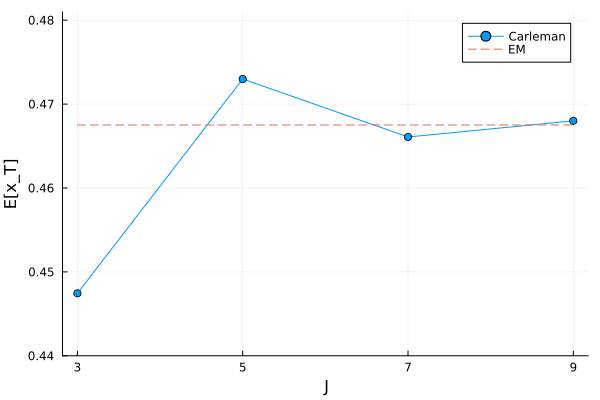

In [106]:
plot(Js, expxCarVariousJ, label="Carleman", xlabel="J", ylabel="E[x_T]", marker=:circle, xticks=3:2:9, ylims=(0.44, 0.481))
plot!(x -> xBench, label="EM", linestyle=:dash)

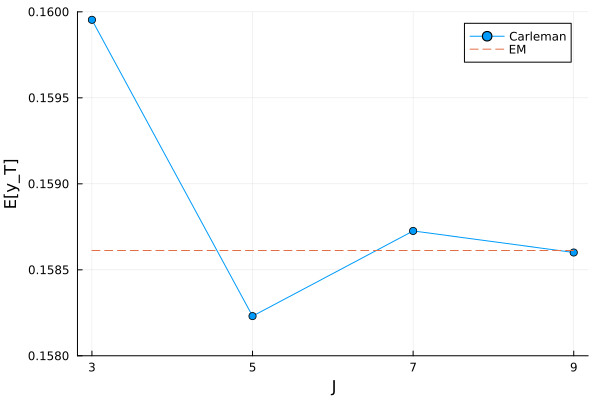

In [108]:
plot(Js, expyCarVariousJ, label="Carleman", xlabel="J", ylabel="E[y_T]", marker=:circle, xticks=3:2:9, ylims=(0.158, 0.16))
plot!(x -> yBench, label="EM", linestyle=:dash)

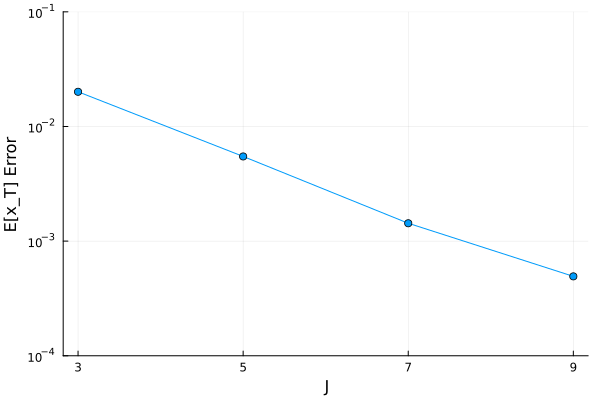

In [109]:
plot(Js, abs.(expxCarVariousJ .- xBench), label="Carleman", xlabel="J", ylabel="E[x_T] Error", marker=:circle, yscale=:log10, ylims=(1e-4, 1e-1), xticks=3:2:9, legend=false)

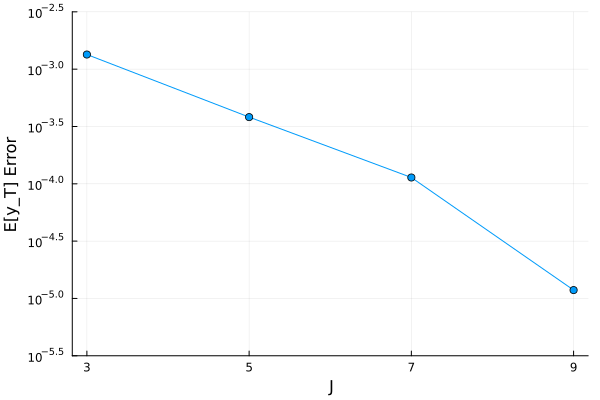

In [112]:
plot(Js, abs.(expyCarVariousJ .- yBench), label="Carleman", xlabel="J", ylabel="E[y_T] Error", marker=:circle, yscale=:log10, ylims=(10^(-5.5), 10^(-2.5)), xticks=3:2:9, legend=false)

In [101]:
eta = minimum(abs.(eigvals(A)))

0.5

In [102]:
alphaF = norm(F, 2)

0.7071067811865476

In [103]:
condLHS = [(J + 0.5 + 1 / (2 * J)) * sigma^2 * gamma^2 + alphaF / gamma^2 for J in Js]

4-element Vector{Float64}:
 9.132168098165177
 9.286834764831845
 9.44454905054613
 9.60327920927629

In [104]:
println(2 * alphaF * U^2)
println(eta * exp(-eta * tEnd))

17.677669529663692
0.38940039153570244
